<a href="https://colab.research.google.com/github/wachu1997/automation_robotics_lab_copy/blob/master/koncowe_lab/lab_auto_2_ver_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorium 2: Problem mieszania — zaprojektuj tanią recepturę

[![Otwórz w Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AdoHaha/automation_robotics_lab/blob/master/pl/lab_auto_2.ipynb)

Zrobotyzowany mieszalnik przygotowuje **100 kg przykładowej mieszanki karmy dla zwierząt**. Pięć składników różni się ceną i składem. Czy można spełnić wymagania jakościowe bez nadmiernych wydatków?

To klasyczny **liniowy problem mieszania**: wybieramy ilości składników, minimalizujemy koszt i spełniamy wymagania dotyczące średnich ważonych. Podobne modele stosuje się do stopów metali, paliw, nawozów i produkcji żywności.

W laboratorium 0 pojawiły się tabele w Pythonie, wykresy i elementy sterujące; w laboratorium 1 PuLP pomagał wybrać strukturę produkcji. Tutaj te same narzędzia służą do wyboru receptury. Przeanalizuj recepturę, jednostki i zapasy względem wymagań, a następnie zbadaj wrażliwość wyniku i dodaj własny element sterujący. Funkcje sprawdzające i rysujące ułatwiają eksperymentowanie z równaniami modelu i jego rozwiązaniami.

W tym ćwiczeniu:

- zamienisz udziały procentowe na ograniczenia liniowe z zachowaniem zgodności jednostek;
- zbudujesz i zinterpretujesz model minimalizacji w PuLP;
- sprawdzisz jakość receptury, ograniczenia aktywne i brak rozwiązania dopuszczalnego;
- zbadasz kompromis koszt–jakość za pomocą wykresów, suwaków i lokalnej analizy wrażliwości;
- uzasadnisz rekomendację receptury wynikami.

Uruchamiaj komórki od góry do dołu, wybierając **Środowisko wykonawcze → Uruchom wszystko** w Google Colab. Wszystkie dane i diagramy znajdują się w notatniku. Instalacja pakietów wymaga jednorazowego połączenia z internetem; eksperymenty nie wymagają zewnętrznych plików. Uproszczone składy i ceny służą nauce, a nie opracowaniu rzeczywistej karmy.

Nazwy w kodzie pozostają angielskie: `chicken` — kurczak, `beef` — wołowina, `eggs` — jaja, `milk` — mleko, `plant_filler` — wypełniacz roślinny; `protein` — białko, `fat` — tłuszcz, `moisture` — zawartość wody. Pozwala to używać tych samych nazw w tabelach, indeksowaniu i kolejnych laboratoriach. `Optimal` oznacza znalezione rozwiązanie optymalne, a `Infeasible` — brak rozwiązania dopuszczalnego.

In [1]:
# Zainstaluj biblioteki w środowisku notatnika, w tym używaną w kursie wersję PuLP.
%pip install -q 'pulp>=3.3,<4' numpy pandas matplotlib ipywidgets

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, clear_output
import ipywidgets as widgets
import pulp

# Colab wymaga tego do wyświetlania widżetów; zwykły Jupyter nie.
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
SOLVER = pulp.PULP_CBC_CMD(msg=False)
print("PuLP", pulp.__version__, "| CBC dostępny:", bool(SOLVER.available()))
if not SOLVER.available():
    raise RuntimeError("Brak CBC. Uruchom komórkę instalacji w świeżym środowisku Colab.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.4/16.4 MB 35.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 64.2 MB/s eta 0:00:00
PuLP 3.3.2 | CBC dostępny: True


## 1. Przeczytaj opis receptury

Zespół zakupowy dostarcza pięć składników. Mieszalnik może odmierzać ułamkowe ilości kilogramów, więc ilości są **zmiennymi ciągłymi**. Masa receptury musi być dokładnie równa zadanej masie partii.

Każdy wiersz poniżej opisuje **jeden kilogram** składnika. Na przykład `protein = 0.38` oznacza 0,38 kg białka na kg kurczaka, czyli 38% masy. Pozostałą masę mogą stanowić węglowodany, popiół i inne substancje; podane udziały nie muszą sumować się do jedności.

Granice udziałów odzwierciedlają praktyczne reguły receptury: co najmniej 10% kurczaka i 5% wypełniacza roślinnego oraz nie więcej niż podane udziały maksymalne. Są to ograniczenia proporcji, a nie zapasu magazynowego. Kolumny `cost_pln_per_kg`, `min_share` i `max_share` oznaczają odpowiednio cenę w PLN/kg oraz minimalny i maksymalny udział masowy.

In [2]:
# Umieść ceny i składy na kg oraz granice udziałów w notatniku, aby odtwarzać eksperymenty.
ingredients = pd.DataFrame([
    # nazwa,      PLN/kg, białko, tłuszcz, woda, udział min., udział maks.
    ("chicken",      6.95,   0.380, 0.090, 0.46, 0.10, 0.60),
    ("beef",         9.60,   0.340, 0.170, 0.40, 0.00, 0.45),
    ("eggs",         5.40,   0.130, 0.110, 0.72, 0.00, 0.25),
    ("milk",         1.15,   0.034, 0.033, 0.88, 0.00, 0.20),
    ("plant_filler", 1.05,   0.160, 0.030, 0.10, 0.05, 0.35),
], columns=["ingredient", "cost_pln_per_kg", "protein", "fat", "moisture",
            "min_share", "max_share"]).set_index("ingredient")

# Zachowaj kolory składników w diagramie, wykresach receptury i seriach badań jakości.
COLORS = dict(zip(ingredients.index,
                  ["#4393c3", "#b35806", "#e8b923", "#8073ac", "#49a06c"]))
display(ingredients)

,cost_pln_per_kg,protein,fat,moisture,min_share,max_share
ingredient,,,,,,
chicken,6.95,0.380,0.090,0.46,0.10,0.60
beef,9.60,0.340,0.170,0.40,0.00,0.45
eggs,5.40,0.130,0.110,0.72,0.00,0.25
milk,1.15,0.034,0.033,0.88,0.00,0.20
plant_filler,1.05,0.160,0.030,0.10,0.05,0.35


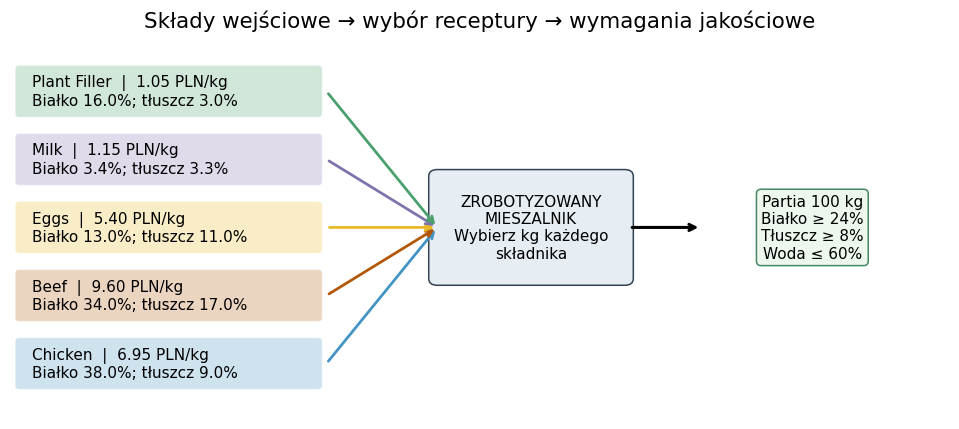

In [3]:
# Narysuj składniki, strzałki i wynik mieszania bez zewnętrznych plików graficznych.
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.set(xlim=(0, 11), ylim=(-0.8, 4.8))
ax.axis("off")
for y, (name, row) in enumerate(ingredients.iterrows()):
    box = FancyBboxPatch((0.1, y - 0.33), 3.5, 0.66, boxstyle="round,pad=0.05",
                         facecolor=COLORS[name], edgecolor="white", alpha=0.25)
    ax.add_patch(box)
    ax.text(0.25, y, f"{name.replace('_', ' ').title()}  |  {row.cost_pln_per_kg:.2f} PLN/kg"
            f"\nBiałko {row.protein:.1%}; tłuszcz {row.fat:.1%}", va="center", fontsize=10)
    ax.annotate("", xy=(5, 2), xytext=(3.7, y),
                arrowprops={"arrowstyle": "->", "color": COLORS[name], "lw": 1.8})
ax.add_patch(FancyBboxPatch((5, 1.25), 2.2, 1.5, boxstyle="round,pad=0.1",
                           facecolor="#e6edf3", edgecolor="#345"))
ax.text(6.1, 2, "ZROBOTYZOWANY\nMIESZALNIK\nWybierz kg każdego\nskładnika", ha="center", va="center")
ax.annotate("", xy=(8.1, 2), xytext=(7.25, 2), arrowprops={"arrowstyle": "->", "lw": 2})
ax.text(9.4, 2, "Partia 100 kg\nBiałko ≥ 24%\nTłuszcz ≥ 8%\nWoda ≤ 60%", ha="center", va="center",
        bbox={"boxstyle": "round", "facecolor": "#edf7ed", "edgecolor": "#486"})
ax.set_title("Składy wejściowe → wybór receptury → wymagania jakościowe", fontsize=14)
plt.show()

### Przewidź wynik przed uruchomieniem

1. Który składnik jest najtańszy? Dlaczego receptura złożona tylko z niego może nie spełniać wymagań?
2. Czy składnik o największej zawartości białka jest zawsze najlepszym zakupem? Porównaj **koszt jednego kg białka**, a następnie wyjaśnij, dlaczego sam ten wskaźnik nie wystarcza do wyboru całej receptury.
3. Jeżeli masa partii wzrośnie dwukrotnie, a wszystkie reguły są procentowe, czy udziały składników powinny się zmienić?

1. Analiza składników i wymagań
Najtańszy składnik: Najtańszym składnikiem jest wypełniacz roślinny (plant_filler) w cenie 1.05 PLN/kg.

Dlaczego sama receptura z niego może nie spełnić wymagań?

Ma on tylko 16% białka (wymagane jest co najmniej 24%).
Ma tylko 3% tłuszczu (wymagane jest co najmniej 8%).

Dodatkowo ograniczenia udziału składnika określają, że maksymalny udział wypełniacza wynosi 35% (max_share = 0.35), więc nie można przygotować mieszanki składającej się w 100% z tego składnika.

Czy składnik o największej zawartości białka to najlepszy zakup?

Najwięcej białka ma kurczak (chicken): 38% (koszt 6.95 PLN/kg).

Obliczmy koszt 1 kg czystego białka dla każdego składnika:

Kurczak (chicken): $6.95 / 0.38 \approx 18.29$$6.95 / 0.38 \approx 18.29$ PLN/kg białka

Wołowina (beef): $9.60 / 0.34 \approx 28.24$$9.60 / 0.34 \approx 28.24$ PLN/kg białka

Jaja (eggs): $5.40 / 0.13 \approx 41.54$$5.40 / 0.13 \approx 41.54$ PLN/kg białka

Mleko (milk): $1.15 / 0.034 \approx 33.82$$1.15 / 0.034 \approx 33.82$ PLN/kg białka

Wypełniacz (plant_filler): $1.05 / 0.16 \approx 6.56$$1.05 / 0.16 \approx 6.56$ PLN/kg białka

Wniosek:

 Najtańszym źródłem białka jest wypełniacz roślinny (6.56 PLN za kg białka), a drugim w kolejności jest kurczak (18.29 PLN za kg białka).

Dlaczego sam ten wskaźnik nie wystarcza?

 Sam wskaźnik kosztu białka nie uwzględnia innych wymagań (tłuszczu, limitu wody) oraz ograniczeń technologicznych (np. maksymalnych i minimalnych udziałów składników w gotowym produkcie). Przykładowo, wypełniacz roślinny ma bardzo mało tłuszczu i za mało białka w czystej masie, by samemu osiągnąć próg 24% w całej partii.

Podwojenie masy partii:

Jeśli wszystkie reguły są wyrażone procentowo, udziały procentowe składników nie powinny się zmienić. Model liniowy przeskaluje się proporcjonalnie – zapotrzebowanie na każdy składnik w kilogramach wzrośnie dokładnie dwukrotnie, ale ich procentowy stosunek w mieszance pozostanie identyczny.

## 2. Przykład wprowadzający: tylko kurczak i wypełniacz roślinny

Na chwilę pomiń tłuszcz, wodę i granice udziałów. Przygotuj 100 kg mieszanki o zawartości białka co najmniej 24%. Niech $c$ oznacza kg kurczaka, a $f$ — kg wypełniacza:

$$\min 6.95c + 1.05f,\qquad c+f=100,\qquad 0.38c+0.16f\geq24,\qquad c,f\geq0.$$

Ręcznie podstaw $f=100-c$. Jaka jest najmniejsza dopuszczalna wartość $c$? Ponieważ kurczak jest droższy, receptura na tej granicy jest najtańszym rozwiązaniem dopuszczalnym. Przewidź wynik przed uruchomieniem wersji w PuLP.

In [ ]:
# Zbuduj model kosztu dwóch składników, aby pokazać każde równanie przed uogólnieniem.
warmup = pulp.LpProblem("Two_ingredient_recipe", pulp.LpMinimize)
chicken_kg = pulp.LpVariable("chicken_kg", lowBound=0)
filler_kg = pulp.LpVariable("filler_kg", lowBound=0)
warmup += 6.95 * chicken_kg + 1.05 * filler_kg, "Cost_PLN"
warmup += chicken_kg + filler_kg == 100, "Batch_kg"
warmup += 0.38 * chicken_kg + 0.16 * filler_kg >= 24, "Protein_kg"
# Sprawdź status rozwiązania przed rysowaniem lub odczytem receptury.
warmup.solve(SOLVER)
warmup_status = pulp.LpStatus[warmup.status]
print("Status:", warmup_status)
if warmup_status == "Optimal":
    print(f"Kurczak: {chicken_kg.value():.2f} kg; wypełniacz: {filler_kg.value():.2f} kg")
    print(f"Koszt: {pulp.value(warmup.objective):.2f} PLN")
    # Przy filler = 100 - chicken wspólna siatka pokazuje jakość i koszt.
    grid = np.linspace(0, 100, 301)
    protein_percent = 0.38 * grid + 0.16 * (100 - grid)
    costs = 6.95 * grid + 1.05 * (100 - grid)
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    axes[0].plot(grid, protein_percent)
    axes[0].axhline(24, color="#ba332b", linestyle="--", label="wymaganie 24%")
    axes[0].fill_between(grid, 0, 40, where=protein_percent >= 24, color="#68ab75", alpha=0.15)
    axes[0].set(xlabel="Kurczak w partii 100 kg (kg)", ylabel="Białko (%)", ylim=(0, 40))
    axes[0].legend()
    axes[1].plot(grid, costs)
    axes[1].scatter([chicken_kg.value()], [pulp.value(warmup.objective)], color="#ba332b",
                    zorder=3, label="Najtańsza receptura dopuszczalna")
    axes[1].set(xlabel="Kurczak w partii 100 kg (kg)", ylabel="Koszt partii (PLN)")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

## 3. Od dwóch składników do pełnego modelu liniowego

Niech $x_i$ oznacza **kg składnika $i$**, a $B=100$ kg — stałą masę partii. Dla każdego składnika $c_i$ to cena w PLN/kg, $p_i$, $f_i$ i $m_i$ to udziały masowe substancji, a $l_i$, $u_i$ — granice udziału składnika.

$$\begin{aligned}
\min\quad &\sum_i c_i x_i &&\text{koszt w PLN}\\
\text{przy ograniczeniach}\quad &\sum_i x_i=B &&\text{masa partii w kg}\\
&\sum_i p_i x_i\geq 0.24B &&\text{co najmniej 24 kg białka na 100 kg}\\
&\sum_i f_i x_i\geq 0.08B &&\text{co najmniej 8 kg tłuszczu na 100 kg}\\
&\sum_i m_i x_i\leq 0.60B &&\text{co najwyżej 60 kg wody na 100 kg}\\
&l_i B\leq x_i\leq u_i B &&\text{granice udziału składnika.}
\end{aligned}$$

**Dlaczego model jest liniowy?** Średnia ważona zawartości białka wynosi $\sum_i p_i x_i/B$. Ponieważ $B$ jest dodatnim, stałym parametrem, mnożymy obie strony wymagania procentowego przez $B$. Wszystkie współczynniki są stałe; nigdy nie mnożymy dwóch zmiennych decyzyjnych. Model oparty na udziałach $s_i=x_i/B$ także jest liniowy i ma ograniczenie $\sum_i s_i=1$.

**Sprawdzenie jednostek:** `(kg białka / kg składnika) × kg składnika = kg białka`. Wpisanie `24` zamiast `0.24` po prawej stronie wymagałoby 2400 kg białka w partii o masie 100 kg.

Najpierw przeczytaj model zapisany bez funkcji pomocniczej. Dopasuj każdą linię kodu do odpowiedniej linii równań.

In [4]:
# Zmienne opisują kg składników; stała masa partii przelicza procenty na wymagane kg.
batch_kg = 100
full_model = pulp.LpProblem("Five_ingredient_recipe", pulp.LpMinimize)
x = {name: pulp.LpVariable(f"kg_{name}", lowBound=0) for name in ingredients.index}
full_model += pulp.lpSum(ingredients.loc[i, "cost_pln_per_kg"] * x[i] for i in x), "Cost_PLN"
full_model += pulp.lpSum(x.values()) == batch_kg, "Batch_kg"
full_model += pulp.lpSum(ingredients.loc[i, "protein"] * x[i] for i in x) >= 0.24 * batch_kg, "Protein_kg"
full_model += pulp.lpSum(ingredients.loc[i, "fat"] * x[i] for i in x) >= 0.08 * batch_kg, "Fat_kg"
full_model += pulp.lpSum(ingredients.loc[i, "moisture"] * x[i] for i in x) <= 0.60 * batch_kg, "Moisture_kg"
for i in x:
    full_model += x[i] >= ingredients.loc[i, "min_share"] * batch_kg, f"Min_{i}"
    full_model += x[i] <= ingredients.loc[i, "max_share"] * batch_kg, f"Max_{i}"
# Odczytaj ilości dopiero po znalezieniu optimum pełnego modelu.
full_model.solve(SOLVER)
print("Status:", pulp.LpStatus[full_model.status])
if full_model.status == pulp.LpStatusOptimal:
    display(pd.Series({i: x[i].value() for i in x}, name="Ilość (kg)").to_frame())
    print(f"Minimalny koszt: {pulp.value(full_model.objective):.2f} PLN")

Status: Optimal


,Ilość (kg)
chicken,24.956609
beef,24.689586
eggs,0.000000
milk,15.353805
plant_filler,35.000000


Minimalny koszt: 464.88 PLN


### Zadanie 1 — obejrzyj i zmień model

- **Przewidź:** Które ograniczenia powinny być aktywne, gdy model unika drogich składników?
- **Uruchom:** Porównaj obliczoną recepturę ze swoim przewidywaniem.
- **Zmień:** W modelu zapisanym bez funkcji podnieś wymaganie białka z `0.24` do `0.28`. Uruchom tę komórkę ponownie i porównaj koszt oraz ilości. Następnie przywróć `0.24`.
- **Wyjaśnij:** Dlaczego minimalne wymaganie używa `>=`, a ograniczenie wody — `<=`? Dlaczego zaokrąglenie każdej ilości do pełnych kg może naruszyć wymagania?

1. Przewidywanie aktywnych ograniczeń (unikając drogich składników)
- Przewidywanie: Aby zminimalizować koszty, solver będzie chciał użyć jak najwięcej najtańszych składników (czyli plant_filler w cenie 1.05 PLN/kg oraz milk w cenie 1.15 PLN/kg) i jak najmniej najdroższych składników (czyli beef w cenie 9.60 PLN/kg oraz chicken w cenie 6.95 PLN/kg).
- Spodziewane ograniczenia aktywne (osiągnięte dokładnie na granicy):
  - Max_plant_filler (osiągnie górną granicę 35%, ponieważ jest najtańszy i chcemy go jak najwięcej).
  - Min_chicken (osiągnie dolną granicę 10%, bo kurczak jest drogi, ale musimy go użyć ze względu na warunek technologiczny).
  - Min_beef (osiągnie dolną granicę 0%, czyli nie zostanie w ogóle wybrany).
  - Protein_kg (ograniczenie jakościowe białka ≥ 24% powinno być aktywne, ponieważ tanie składniki mają mało białka i musimy precyzyjnie dozować droższe składniki bogate w białko tylko do wymaganego minimum).
  - Moisture_kg (ograniczenie wody ≤ 60% również może być aktywne, ponieważ tanie mleko ma aż 88% wody, co drastycznie ogranicza możliwość jego bezkarnego dodawania).

2. Porównanie po zmianie białka z 24% na 28%
- Dla 24% białka (wariant bazowy): Koszt wynosi 464.88 PLN.
- Dla 28% białka: Zapotrzebowanie na białko rośnie. Solver musi zmniejszyć ilość tańszych, uboższych w białko składników (takich jak mleko czy wypełniacz) na rzecz droższego kurczaka lub wołowiny. Spowoduje to wyraźny wzrost kosztu całej partii oraz zmianę proporcji (udział kurczaka wzrośnie powyżej minimalnego poziomu 10%).

3. Dlaczego minimalne wymaganie używa >=, a wody <=?
- Białko (i tłuszcz) jako pożądane składniki odżywcze: Chcemy zagwarantować, że karma ma co najmniej zadaną wartość odżywczą (jakość premium), stąd warunek większe lub równe (≥). Przekroczenie tego progu nie jest błędem jakościowym (choć kosztowym zazwyczaj tak).
- Woda (wilgotność) jako ograniczenie technologiczne: Nadmiar wody powoduje, że karma byłaby zbyt płynna lub psułaby się zbyt szybko. Chcemy zagwarantować, że wilgotność nie przekroczy maksymalnego dopuszczalnego poziomu, stąd warunek mniejsze lub równe (≤).

4. Dlaczego zaokrąglenie ilości do pełnych kg może naruszyć wymagania?
Rozwiązanie problemu liniowego (LP) znajduje się często dokładnie w punkcie przecięcia linii ograniczających (w tzw. wierzchołku obszaru dopuszczalnego). Jeśli zaokrąglimy ułamkowe wyniki (np. 36.36 kg kurczaka do 36 kg lub 37 kg):
- Zaokrąglenie w dół droższego składnika bogatego w białko może spowodować, że zawartość białka w gotowej partii spadnie poniżej wymaganych 24% (naruszenie ograniczenia jakościowego).
- Zaokrąglenie w górę może spowodować przekroczenie dopuszczalnej masy partii (suma mas nie będzie równa dokładnie 100 kg) lub przekroczenie limitu wilgotności.

## 4. Solver wielokrotnego użytku ze sprawdzaniem wyniku

Budowanie nowego modelu przy każdym eksperymencie zapobiega przypadkowemu gromadzeniu starych ograniczeń. Poniższe funkcje oddzielają prostą granicę diagnostyczną od kompletnego modelu optymalizacyjnego.

### Funkcja pomocnicza: optymistyczna granica zawartości białka

`maximum_protein_from_share_limits(data)` przyjmuje tabelę składników z udziałami białka oraz dolnymi i górnymi granicami udziału składników. Rezerwuje udziały minimalne, a następnie przydziela pozostały udział składnikom o największej zawartości białka, do ich limitów. Zwraca jeden **ułamek określający udział białka**, a nie recepturę; niczego nie wyświetla i nie wywołuje solvera. Pomija tłuszcz i wodę, więc może wykazać niemożliwość żądania, ale nie dowodzi dopuszczalności pełnej receptury. Użycie tej samej funkcji w diagnostyce nieudanego rozwiązania i w samodzielnym eksperymencie zapewnia spójne wyjaśnienie. Minimalne udziały muszą mieścić się w jednej partii, a maksymalne — umożliwiać jej wypełnienie.

In [5]:
def maximum_protein_from_share_limits(data):
    """Zwróć optymistyczną maksymalną zawartość białka przy granicach udziałów.

    data jest tabelą DataFrame indeksowaną składnikami, z protein (kg białka/kg
    składnika), min_share i max_share jako ułamkami. Suma minimów nie może
    przekraczać jedności, suma maksimów musi wynosić co najmniej jeden, a każde
    minimum nie może przekraczać maksimum. Brak argumentów domyślnych.
    Zarezerwuj minima i wypełnij resztę według malejącej zawartości białka.
    Zwróć ułamek float, pomijając tłuszcz i wodę; bez wyświetlania, solvera
    ani globalnej tabeli składników. Dane wejściowe nie są modyfikowane."""
    # Zarezerwuj wymagane składniki przed przydzieleniem pozostałego udziału partii.
    shares = data["min_share"].copy()
    remaining = 1.0 - shares.sum()
    # Przydział zachłanny jest poprawny dla tej granicy jednej cechy, a nie dla pełnego LP mieszania.
    for name in data.sort_values("protein", ascending=False).index:
        addition = min(remaining, data.loc[name, "max_share"] - shares[name])
        shares[name] += addition
        remaining -= addition
    return float((shares * data["protein"]).sum())

### Funkcja pomocnicza: rozwiąż i sprawdź jedną recepturę

`solve_blend(batch_kg=100, min_protein=0.24, min_fat=0.08, max_moisture=0.60,
chicken_cost_multiplier=1.0, data=None)` przyjmuje masę partii w kg, trzy granice jakości jako ułamki, bezwymiarowy mnożnik ceny kurczaka (cena bazowa w PLN/kg) i opcjonalną tabelę składników. `data=None` kopiuje wspólną tabelę `ingredients`; przekazana własna tabela także jest kopiowana, więc eksperymenty nie zmieniają danych bazowych. Na przykład `solve_blend(batch_kg=200, min_protein=0.28)` zmienia tylko masę partii i wymaganie białka.

Funkcja sprawdza dane, buduje te same równania kosztu i jakości co powyżej, rozwiązuje model wspólnym solverem `SOLVER` i sprawdza status. Dla optimum ponownie oblicza masę, jakość i zapasy względem wymagań, po czym zwraca słownik z `recipe` (recepturą), `quality` (jakością), `constraints` (ograniczeniami), `quantities_kg` (ilościami) i `cost_pln` (kosztem), a także model i status. Niczego nie wyświetla. Tabele, wykresy, serie eksperymentów i elementy sterujące korzystają z tej samej sprawdzonej struktury.

**Najpierw sprawdź status.** Gdy nie znaleziono optimum, wynik zawiera diagnostykę, a pola rozwiązania mają wartość `None`. Funkcja kończy działanie przed odczytem zmiennych decyzyjnych, ponieważ wartości pozostawione przez solver po stwierdzeniu braku rozwiązania dopuszczalnego nie opisują użytecznej receptury. Optymistyczna granica białka wskazuje jedną możliwą przyczynę; wzajemne oddziaływanie ograniczeń jakości może wymagać dokładniejszej analizy.

In [6]:
def solve_blend(batch_kg=100, min_protein=0.24, min_fat=0.08,
                max_moisture=0.60, chicken_cost_multiplier=1.0, data=None):
    """Rozwiąż i sprawdź ciągły liniowy problem mieszania, bez wyświetlania.

    batch_kg=100 to dodatnia masa w kg; min_protein=0.24, min_fat=0.08 oraz
    max_moisture=0.60 to udziały masowe. chicken_cost_multiplier=1.0 skaluje
    wyłącznie cenę kurczaka w PLN/kg. data=None kopiuje globalną ingredients;
    opcjonalny indeksowany DataFrame podaje ceny, składy i granice udziałów.
    Korzysta z globalnego SOLVER i maximum_protein_from_share_limits w diagnostyce.

    Zwraca słownik ze status, model, batch_kg i komunikatami diagnostics.
    Optimum zawiera także cost_pln, quantities_kg (Series), recipe (DataFrame
    z kg, share_pct i kosztami składników), quality (osiągnięte/wymagane udziały,
    zapasy i sprawdzenia) oraz constraints (osiągnięte/graniczne kg, jednostki,
    luz/nadwyżkę, aktywność i ceny dualne LP). Pola rozwiązania pozostają None,
    jeżeli status nie jest Optimal. Kopiuje dane; błędne dane wywołują ValueError."""
    # Pracuj na kopii, aby zmiana ceny nie wpływała na dane innych eksperymentów.
    table = ingredients.copy(deep=True) if data is None else data.copy(deep=True)
    # Sprawdź jednostki, ułamki, ceny i granice udziałów przed budowaniem modelu.
    parameters = [batch_kg, min_protein, min_fat, max_moisture, chicken_cost_multiplier]
    if not np.isfinite(parameters).all() or batch_kg <= 0 or chicken_cost_multiplier < 0:
        raise ValueError("Masa partii musi być dodatnia i skończona, a mnożnik ceny — nieujemny i skończony.")
    if not all(0 <= v <= 1 for v in [min_protein, min_fat, max_moisture]):
        raise ValueError("Granice składników odżywczych muszą być ułamkami od 0 do 1.")
    required = ["cost_pln_per_kg", "protein", "fat", "moisture", "min_share", "max_share"]
    if table.empty or not table.index.is_unique or "chicken" not in table.index:
        raise ValueError("Nazwy składników muszą być unikalne i zawierać chicken.")
    if not np.isfinite(table[required].to_numpy()).all():
        raise ValueError("Dane składników muszą zawierać skończone wartości liczbowe.")
    fractions = table[["protein", "fat", "moisture", "min_share", "max_share"]]
    if ((fractions < 0) | (fractions > 1)).any().any():
        raise ValueError("Skład i udziały muszą być ułamkami z przedziału [0, 1].")
    if (table["cost_pln_per_kg"] < 0).any() or (table.min_share > table.max_share).any():
        raise ValueError("Koszty muszą być nieujemne; udziały minimalne nie mogą przekraczać maksymalnych.")
    # Zbuduj nowy model: koszt jako funkcja celu, bilans masy, jakość i granice udziałów.
    table.loc["chicken", "cost_pln_per_kg"] *= chicken_cost_multiplier
    model = pulp.LpProblem("Blend", pulp.LpMinimize)
    variables = {i: pulp.LpVariable(f"kg_{i}", lowBound=0) for i in table.index}
    model += pulp.lpSum(table.loc[i, "cost_pln_per_kg"] * variables[i] for i in table.index), "Cost_PLN"
    model += pulp.lpSum(variables.values()) == batch_kg, "Batch_kg"
    model += pulp.lpSum(table.loc[i, "protein"] * variables[i] for i in table.index) >= min_protein * batch_kg, "Protein_kg"
    model += pulp.lpSum(table.loc[i, "fat"] * variables[i] for i in table.index) >= min_fat * batch_kg, "Fat_kg"
    model += pulp.lpSum(table.loc[i, "moisture"] * variables[i] for i in table.index) <= max_moisture * batch_kg, "Moisture_kg"
    for i in table.index:
        model += variables[i] >= table.loc[i, "min_share"] * batch_kg, f"Min_{i}"
        model += variables[i] <= table.loc[i, "max_share"] * batch_kg, f"Max_{i}"
    # Najpierw zapisz status; nieudane rozwiązanie nie może udostępniać pozostałych wartości zmiennych.
    model.solve(SOLVER)
    result = {"status": pulp.LpStatus[model.status], "model": model,
              "batch_kg": batch_kg, "cost_pln": None, "quantities_kg": None,
              "recipe": None, "quality": None, "constraints": None, "diagnostics": []}
    if model.status != pulp.LpStatusOptimal:
        # Wyjaśnij naruszenia prostych granic koniecznych; nie obejmują wszystkich konfliktów.
        if table.min_share.sum() > 1 + 1e-9:
            result["diagnostics"].append("Suma minimalnych udziałów składników przekracza 100%.")
        elif table.max_share.sum() < 1 - 1e-9:
            result["diagnostics"].append("Maksymalne udziały składników nie pozwalają wypełnić całej partii.")
        else:
            upper = maximum_protein_from_share_limits(table)
            if min_protein > upper + 1e-9:
                result["diagnostics"].append(
                    f"Wymagana zawartość białka {min_protein:.1%} przekracza górną granicę wynikającą z udziałów {upper:.1%}.")
        if min_fat > table.fat.max() + 1e-9:
            result["diagnostics"].append("Wymagana zawartość tłuszczu przekracza zawartość w najtłustszym składniku.")
        if max_moisture < table.moisture.min() - 1e-9:
            result["diagnostics"].append("Dopuszczalna zawartość wody jest mniejsza niż w najsuchszym składniku.")
        if not result["diagnostics"]:
            result["diagnostics"].append(
                "Prosta granica nie wyjaśnia statusu. Zbadaj współdziałające ograniczenia jakości i udziałów; poluzuj jedno naraz.")
        return result

    # Odczytaj tylko optimum i przelicz udziały oraz koszty w pierwotnych jednostkach.
    quantities = pd.Series({i: variables[i].value() for i in table.index}, name="kg")
    recipe = table.copy()
    recipe["kg"] = quantities
    recipe["share_pct"] = 100 * quantities / batch_kg
    recipe["ingredient_cost_pln"] = quantities * table.cost_pln_per_kg
    targets = {"protein": (min_protein, ">="), "fat": (min_fat, ">="),
               "moisture": (max_moisture, "<=")}
    # Przelicz sumy ważone na procenty i zapasy jakości z właściwym znakiem.
    quality_rows = []
    for nutrient, (target, sense) in targets.items():
        actual = float((quantities * table[nutrient]).sum() / batch_kg)
        margin = actual - target if sense == ">=" else target - actual
        quality_rows.append({"nutrient": nutrient, "actual_pct": 100 * actual,
                             "target_pct": 100 * target, "rule": sense,
                             "margin_percentage_points": 100 * margin,
                             "meets_target": margin >= -1e-7})

    # Opisz każde ograniczenie wartością osiągniętą, granicą, zapasem i lokalną ceną dualną.
    checks = []
    for name, constraint in model.constraints.items():
        # PuLP zapisuje (lewa − prawa); luz lub nadwyżka z właściwym znakiem są nieujemne dla rozwiązania dopuszczalnego.
        residual = float(pulp.value(constraint))
        slack = (-residual if constraint.sense == pulp.LpConstraintLE else
                 residual if constraint.sense == pulp.LpConstraintGE else abs(residual))
        units = {"Protein_kg": "kg białka", "Fat_kg": "kg tłuszczu",
                 "Moisture_kg": "kg wody"}.get(name, "kg składnika/partii")
        checks.append({"constraint": name, "sense": {0: "=", 1: ">=", -1: "<="}[constraint.sense],
                       "achieved_kg": residual - constraint.constant,
                       "bound_kg": -constraint.constant, "units": units,
                       "slack_or_surplus_kg": slack, "binding": abs(slack) <= 1e-5,
                       "dual_pln_per_rhs_kg": constraint.pi})
    quality = pd.DataFrame(quality_rows).set_index("nutrient")
    constraint_table = pd.DataFrame(checks).set_index("constraint")
    # Niezależnie sprawdź rachunki przed przedstawieniem rozwiązania.
    assert abs(quantities.sum() - batch_kg) <= 1e-5 * max(1, batch_kg)
    assert quality.meets_target.all(), "Zwrócona receptura nie spełnia wymagania jakościowego."
    assert (constraint_table.slack_or_surplus_kg >= -1e-5 * max(1, batch_kg)).all()
    result.update(cost_pln=float(pulp.value(model.objective)), quantities_kg=quantities,
                  recipe=recipe, quality=quality, constraints=constraint_table)
    return result


# Zachowaj wynik domyślny, aby bazowe tabele i wykresy opisywały tę samą recepturę.
baseline = solve_blend()
print("Status wariantu bazowego:", baseline["status"])
if baseline["status"] == "Optimal":
    display(baseline["recipe"][["kg", "share_pct", "ingredient_cost_pln"]].round(3))
    display(baseline["quality"].round(4))
    print(f"Koszt = {baseline['cost_pln']:.2f} PLN; {baseline['cost_pln'] / 100:.3f} PLN/kg")

Status wariantu bazowego: Optimal


,kg,share_pct,ingredient_cost_pln
ingredient,,,
chicken,24.957,24.957,173.448
beef,24.690,24.690,237.020
eggs,0.000,0.000,0.000
milk,15.354,15.354,17.657
plant_filler,35.000,35.000,36.750


,actual_pct,target_pct,rule,margin_percentage_points,meets_target
nutrient,,,,,
protein,24.0000,24.0,>=,0.0000,True
fat,8.0000,8.0,>=,-0.0000,True
moisture,38.3672,60.0,<=,21.6328,True


Koszt = 464.88 PLN; 4.649 PLN/kg


## 5. Zobacz rozwiązanie i zapasy względem wymagań

Wykres receptury odpowiada na pytanie **co trafia do mieszalnika**. Wykres jakości pokazuje **czy mieszanka spełnia wymagania**. Linia minimum powinna leżeć na wysokości słupka lub poniżej niego; linia maksimum — na wysokości słupka lub powyżej niego.

**Ograniczenie aktywne** jest spełnione na granicy. Dla reguły `<=` **luz = granica − wartość osiągnięta**, a dla `>=` **nadwyżka = wartość osiągnięta − granica**. W rozwiązaniu dopuszczalnym oba zapasy są nieujemne. Tabela podaje wartości osiągnięte, granice, jednostki i `slack_or_surplus_kg` (luz lub nadwyżkę w kg). Nadwyżka białka to dodatkowe kg białka ponad wymaganie; luz w ograniczeniu wody to niewykorzystana część dopuszczalnej ilości wody.

Tabela jakości przedstawia te same zapasy w **punktach procentowych**. Dla równości kolumna zawiera wartość bezwzględną reszty numerycznej: powinna być bliska zeru i nie stanowi zasobu do wykorzystania. Ograniczenie aktywne ma zerowy zapas z dokładnością do tolerancji numerycznej. Cena dualna odpowiada na inne pytanie: jak zmieni się koszt po przesunięciu granicy.

`plot_blend(result)` przyjmuje słownik zwrócony przez `solve_blend`. Sprawdza status przed odczytem receptury, wypisuje koszt partii, rysuje ilości składników w kg i procentowy skład, a następnie wyświetla tabelę jakości. Przy braku optimum wypisuje diagnostykę. Zwraca `None` i nie rozwiązuje modelu ponownie. Wspólny słownik `COLORS` zapewnia spójny kolor każdego składnika; nowe nazwy otrzymują kolor szary. Użycie tej samej funkcji dla przypadku bazowego, nazwanych eksperymentów i obsługi suwaków ułatwia porównanie statusów i jakości.

Angielskie nagłówki wyników pozostają nazwami używanymi w kodzie: `kg` — masa, `share_pct` — udział procentowy, `ingredient_cost_pln` — koszt składnika, `actual_pct` — udział osiągnięty, `target_pct` — udział wymagany, `margin_percentage_points` — zapas w punktach procentowych, `meets_target` — spełnienie wymagania. W tabeli ograniczeń `achieved_kg` oznacza wartość osiągniętą, `bound_kg` — granicę, `binding` — aktywność, a `dual_pln_per_rhs_kg` — cenę dualną w PLN na dodatkowy kg prawej strony ograniczenia.

Optymalna partia 100 kg: 464.88 PLN (4.649 PLN/kg)


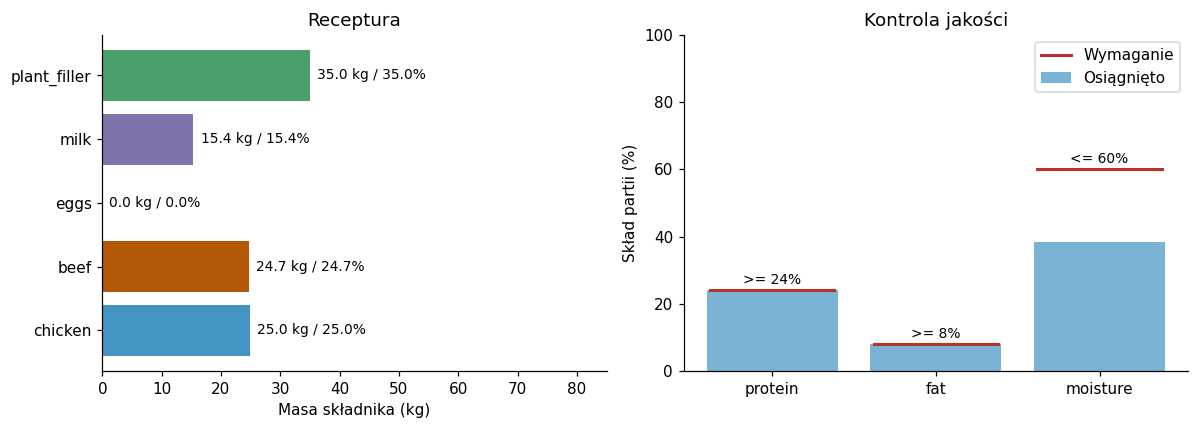

,actual_pct,target_pct,rule,margin_percentage_points,meets_target
nutrient,,,,,
protein,24.0000,24.0,>=,0.0000,True
fat,8.0000,8.0,>=,-0.0000,True
moisture,38.3672,60.0,<=,21.6328,True


,sense,achieved_kg,bound_kg,units,slack_or_surplus_kg,binding,dual_pln_per_rhs_kg
constraint,,,,,,,
Batch_kg,=,100.00000,100.0,kg składnika/partii,0.00000,True,-0.47063
Protein_kg,>=,24.00000,24.0,kg białka,0.00000,True,10.44559
Fat_kg,>=,8.00000,8.0,kg tłuszczu,-0.00000,True,38.34780
Moisture_kg,<=,38.36722,60.0,kg wody,21.63278,False,0.00000
Min_chicken,>=,24.95661,10.0,kg składnika/partii,14.95661,False,0.00000
Max_chicken,<=,24.95661,60.0,kg składnika/partii,35.04339,False,0.00000
Min_beef,>=,24.68959,-0.0,kg składnika/partii,24.68959,False,0.00000
Max_beef,<=,24.68959,45.0,kg składnika/partii,20.31041,False,0.00000
Min_eggs,>=,0.00000,-0.0,kg składnika/partii,0.00000,True,0.00000


In [7]:
def plot_blend(result):
    """Wyświetl wykres receptury i jakości wyniku solve_blend; zwróć None.

    result to słownik solvera ze status/diagnostics, a przy statusie Optimal także
    batch_kg, cost_pln, recipe (kg i share_pct) oraz quality (osiągnięte/wymagane
    procenty i reguły >=/<=). Status inny niż Optimal wyświetla diagnostykę
    bez odczytu rozwiązania. Optimum wyświetla koszt, dwa panele Matplotlib
    i tabelę jakości DataFrame. Korzysta z globalnych COLORS, np, plt i display;
    nie zmienia danych ani nie rozwiązuje modelu ponownie."""
    # Sprawdź status przed odczytem pól liczbowych receptury.
    if result["status"] != "Optimal":
        print("Status:", result["status"], "— brak receptury do narysowania.")
        for message in result["diagnostics"]:
            print(" •", message)
        return
    # Rysuj wyłącznie na podstawie sprawdzonej receptury i tabeli jakości.
    recipe, quality = result["recipe"], result["quality"]
    print(f"Optymalna partia {result['batch_kg']:g} kg: {result['cost_pln']:.2f} PLN"
          f" ({result['cost_pln'] / result['batch_kg']:.3f} PLN/kg)")
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    # Podpisz masy udziałami, aby pokazać oba sposoby opisu ilości.
    axes[0].barh(recipe.index, recipe.kg, color=[COLORS.get(i, "#777") for i in recipe.index])
    for j, (_, row) in enumerate(recipe.iterrows()):
        axes[0].text(row.kg + result["batch_kg"] * 0.012, j,
                     f"{row.kg:.1f} kg / {row.share_pct:.1f}%", va="center", fontsize=9)
    axes[0].set(xlabel="Masa składnika (kg)", title="Receptura", xlim=(0, result["batch_kg"] * 0.85))
    # Porównaj osiągnięty procent każdej cechy z linią minimum lub maksimum.
    positions = np.arange(len(quality))
    axes[1].bar(positions, quality.actual_pct, color="#4393c3", alpha=0.7, label="Osiągnięto")
    for pos, (_, row) in zip(positions, quality.iterrows()):
        axes[1].plot([pos - 0.38, pos + 0.38], [row.target_pct] * 2, color="#ba332b", lw=2)
        axes[1].text(pos, max(row.actual_pct, row.target_pct) + 2,
                     f"{row.rule} {row.target_pct:g}%", ha="center", fontsize=9)
    axes[1].plot([], [], color="#ba332b", lw=2, label="Wymaganie")
    axes[1].set(xticks=positions, xticklabels=quality.index,
                ylabel="Skład partii (%)", title="Kontrola jakości", ylim=(0, 100))
    axes[1].legend()
    plt.tight_layout()
    plt.show()
    # Wyświetl pola tabeli obok kontroli wizualnej, zaokrąglone dla czytelności.
    display(quality.round(4))


plot_blend(baseline)
if baseline["status"] == "Optimal":
    display(baseline["constraints"].round(5))

### Samodzielnie zbuduj wykres

Wykres składa się z **figury** — całego obszaru rysunku — oraz obiektu **axes**, czyli pojedynczego pola wykresu. `ax.barh(labels, values)` rysuje poziomy słupek dla każdej wartości; `ax.set(...)` ustawia opisy osi. Poniżej znajduje się krótki, działający wykres, który możesz zmienić bez czytania całej funkcji rysującej.

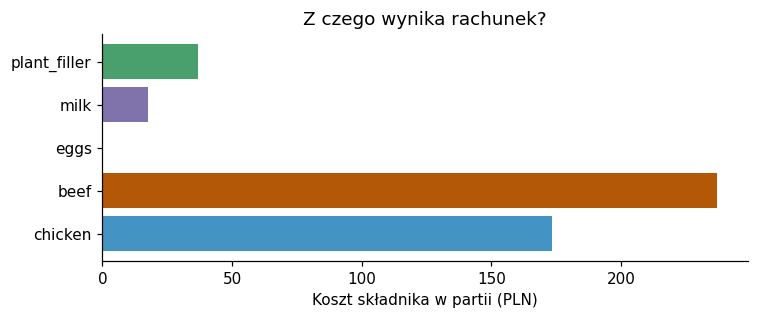

In [8]:
# Narysuj sprawdzone koszty składników w partii, a nie ceny jednostkowe czy niesprawdzone zmienne.
if baseline["status"] == "Optimal":
    fig, ax = plt.subplots(figsize=(7, 3))  # utwórz jedną figurę i jedno pole wykresu
    ax.barh(baseline["recipe"].index, baseline["recipe"].ingredient_cost_pln,
            color=[COLORS[i] for i in baseline["recipe"].index])
    ax.set(xlabel="Koszt składnika w partii (PLN)", title="Z czego wynika rachunek?")
    plt.tight_layout()  # zostaw miejsce na opisy
    plt.show()

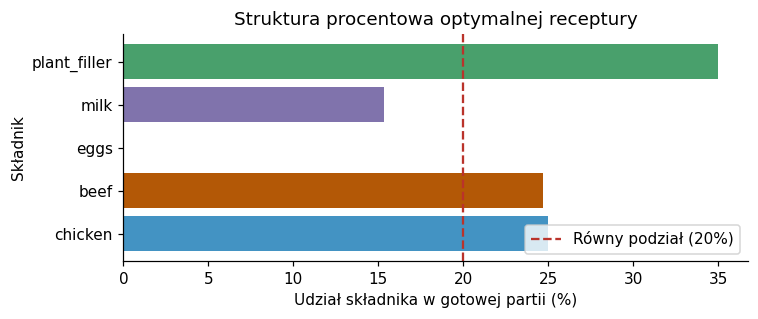

In [9]:
# Zadanie z wykresem: Pokaż udziały procentowe składników z linią odniesienia
if baseline["status"] == "Optimal":
    fig, ax = plt.subplots(figsize=(7, 3))
    # Używamy udziału procentowego (share_pct) zamiast kosztu
    ax.barh(baseline["recipe"].index, baseline["recipe"].share_pct,
            color=[COLORS[i] for i in baseline["recipe"].index])

    # Dodanie pionowej linii odniesienia (np. 20% - równy podział dla 5 składników)
    reference_pct = 20.0
    ax.axvline(reference_pct, color="#ba332b", linestyle="--", lw=1.5,
               label=f"Równy podział ({reference_pct:.0f}%)")

    ax.set(xlabel="Udział składnika w gotowej partii (%)",
           ylabel="Składnik",
           title="Struktura procentowa optymalnej receptury")
    ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()

### Dlaczego pionowa linia 20% to tylko punkt odniesienia, a nie uniwersalne ograniczenie?

Linia równego podziału (20% dla każdego z 5 składników) służy wyłącznie do wizualnego porównania i szybkiej oceny, które składniki dominują w recepturze, a które są marginalizowane. Nie jest to uniwersalne ograniczenie, ponieważ każdy składnik charakteryzuje się skrajnie różną ceną, wartością odżywczą (białko, tłuszcz) i wilgotnością. Wymuszenie równego udziału wszystkich składników drastycznie pogorszyłoby optymalność kosztową lub wręcz uniemożliwiło znalezienie rozwiązania dopuszczalnego.

---

### Zadanie 2 — wyjaśnij recepturę

#### 1. Które składniki osiągają minimalny lub maksymalny udział? Czy pominięcie składnika zawsze oznacza jego niską jakość?
- Maksymalny udział: `plant_filler` osiąga swój techniczny limit górny równy 35.0% (35.0 kg).
- Minimalny udział: `chicken` osiąga swój limit dolny równy 10.0% (jednak w optymalnej recepturze bazowej jego udział wynosi 25.0%, więc nie leży bezpośrednio na dolnej granicy). Składnik `beef` ma dolną granicę 0.0% i w rozwiązaniu wynosi ona 24.7%. Składniki `eggs` i `milk` mają dolny limit 0.0%, przy czym `eggs` wynosi 0.0 kg (został pominięty).
- Czy pominięcie oznacza niską jakość? Nie. Pominięcie składnika (np. jaj `eggs`) oznacza najczęściej, że jest on nieefektywny ekonomicznie w porównaniu do innych źródeł tych samych składników odżywczych (jaja mają wysoki koszt w przeliczeniu na 1 kg białka: ~41.54 PLN, podczas gdy kurczak oferuje znacznie tańsze białko wysokiej jakości za ~18.29 PLN/kg).

#### 2. Które ograniczenia jakości są aktywne? Wskaż tę samą granicę w tabeli i na wykresie.
- Białko (protein): Osiągnięto dokładnie 24.0% (luz/nadwyżka = 0.0). Jest to ograniczenie aktywne. Na wykresie słupkowym prawy czerwony znacznik minimum leży dokładnie na krawędzi niebieskiego słupka. W tabeli ograniczeń wiersz `Protein_kg` ma wartość `slack_or_surplus_kg = 0.0` oraz `binding = True`.
- Tłuszcz (fat): Osiągnięto dokładnie 8.0% (luz/nadwyżka = 0.0). Jest to ograniczenie aktywne (czerwony znacznik na poziomie krawędzi słupka, w tabeli `binding = True`).
- Woda (moisture): Osiągnięto 38.7%, co jest znacznie poniżej maksymalnego limitu 60.0% (`slack_or_surplus_kg = 21.3 kg` zapasu). Ograniczenie nie jest aktywne.

#### 3. Na papierze: dodaj 1 kg najtańszego składnika (plant_filler) i usuń 1 kg kurczaka. Czy mieszanka jest dopuszczalna?
- Białko: Tracimy 1 kg kurczaka (0.38 kg białka) i zyskujemy 1 kg wypełniacza (0.16 kg białka). Bilans netto: -0.22 kg białka. Zawartość białka spada z 24.0 kg do 23.78 kg (23.78%), co narusza wymaganie minimum 24%.
- Tłuszcz: Tracimy 1 kg kurczaka (0.09 kg tłuszczu) i zyskujemy 1 kg wypełniacza (0.03 kg tłuszczu). Bilans netto: -0.06 kg tłuszczu. Zawartość tłuszczu spada z 8.0 kg do 7.94 kg (7.94%), co narusza wymaganie minimum 8%.
- Wniosek: Zmieniona mieszanka jest niedopuszczalna (Infeasible).

#### 4. Porównanie receptury z przykładem dwóch składników. Wyjaśnij różnicę kosztów.
- W przykładzie wprowadzającym (tylko kurczak i wypełniacz) koszt 100 kg wynosił 319.55 PLN, a w modelu pełnym wynosi 464.88 PLN.
- Dlaczego tam koszt był niższy? W przykładzie uproszczonym pominęliśmy ograniczenie tłuszczu (minimum 8%) oraz minimalny udział kurczaka (10%). W pełnym modelu te dodatkowe ograniczenia zmusiły solver do dokupienia drogiej wołowiny (`beef` w cenie 9.60 PLN/kg) i kurczaka, aby zbilansować tłuszcz i białko przy jednoczesnym ograniczeniu maksymalnego udziału taniego wypełniacza roślinnego do 35%.

**Zadanie z wykresem:** zamiast kosztów składników pokaż ich udziały procentowe, a następnie zmień opis osi i tytuł. Dodaj pionową linię przez `ax.axvline(...)` jako sensowny punkt odniesienia dla udziału składnika. Wyjaśnij, dlaczego jest to punkt odniesienia, a nie uniwersalne ograniczenie receptury.

### Zadanie 2 — wyjaśnij recepturę

1. Które składniki osiągają minimalny lub maksymalny udział? Czy pominięcie składnika zawsze oznacza jego niską jakość?
2. Które ograniczenia jakości są aktywne? Wskaż tę samą granicę w tabeli i na wykresie.
3. **Na papierze** dodaj 1 kg najtańszego składnika i usuń 1 kg kurczaka. Przelicz zawartość białka i tłuszczu. Czy zmieniona mieszanka nadal jest dopuszczalna?
4. Porównaj recepturę z przykładem dwóch składników. Wyjaśnij, dlaczego tam koszt był niższy: rozwiązywano model o innym zestawie ograniczeń.

## 6. Ostrzejsze wymaganie może spowodować brak rozwiązania dopuszczalnego

Największy udział białka w pojedynczym składniku wynosi 38%, ale granice udziałów uniemożliwiają użycie samego kurczaka. Aby wyznaczyć konieczną górną granicę białka, zacznij od minimalnych udziałów i wypełnij pozostałą część partii składnikami o najwyższej zawartości białka, do ich limitów. Pomijasz inne wymagania jakościowe, więc jest to **optymistyczna granica górna**, a nie gwarancja dopuszczalnej receptury.

Przewidź, czy da się osiągnąć **36% białka**. Następnie uruchom poniższy scenariusz. Brak rozwiązania dopuszczalnego jest oczekiwanym wynikiem eksperymentu: nie istnieje receptura spełniająca wszystkie reguły. To coś innego niż wyjątek Pythona lub brak solvera.

In [10]:
# Porównaj konieczną granicę wynikającą z udziałów z celowo niemożliwym wymaganiem jakości.
protein_upper_bound = maximum_protein_from_share_limits(ingredients)
print(f"Górna granica białka wynikająca z udziałów: {protein_upper_bound:.1%}")
impossible = solve_blend(min_protein=0.36)
plot_blend(impossible)
assert impossible["status"] == "Infeasible"
assert impossible["quantities_kg"] is None

Górna granica białka wynikająca z udziałów: 35.5%
Status: Infeasible — brak receptury do narysowania.
 • Wymagana zawartość białka 36.0% przekracza górną granicę wynikającą z udziałów 35.5%.


Nowa górna granica białka wynikająca z udziałów: 36.7%
Optymalna partia 100 kg: 645.50 PLN (6.455 PLN/kg)


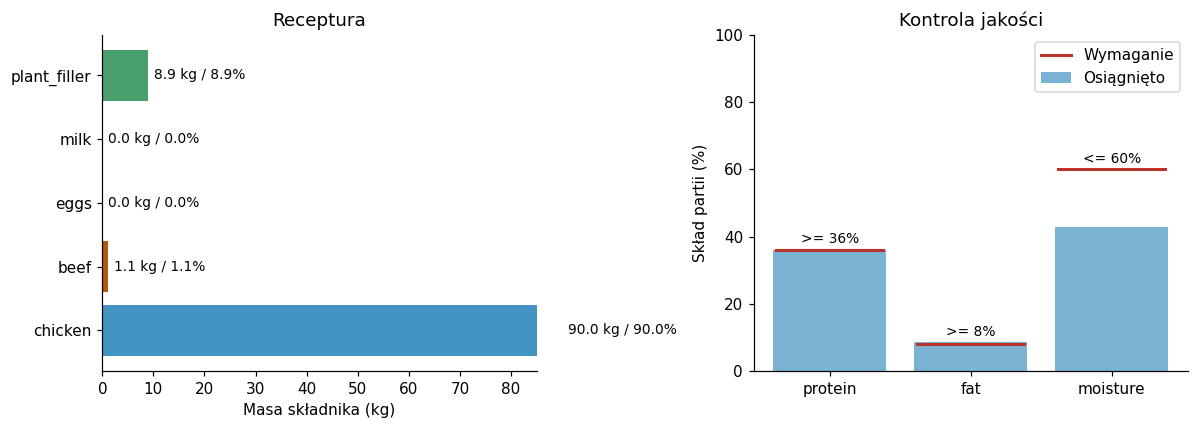

,actual_pct,target_pct,rule,margin_percentage_points,meets_target
nutrient,,,,,
protein,36.0000,36.0,>=,-0.0000,True
fat,8.5556,8.0,>=,0.5556,True
moisture,42.7333,60.0,<=,17.2667,True


In [11]:
# Zadanie 3: Naprawa problemu braku rozwiązania dla 36% białka
# Tworzymy kopię danych, aby nie modyfikować tabeli bazowej
ingredients_modified = ingredients.copy()

# Zmieniamy jedno założenie: zwiększamy dopuszczalny maksymalny udział kurczaka (chicken) z 60% do 90%
ingredients_modified.loc["chicken", "max_share"] = 0.90

# Sprawdzamy optymistyczną granicę górną dla nowego zestawu ograniczeń
new_upper_bound = maximum_protein_from_share_limits(ingredients_modified)
print(f"Nowa górna granica białka wynikająca z udziałów: {new_upper_bound:.1%}")

# Rozwiązujemy model z nowymi parametrami wejściowymi
repaired_recipe = solve_blend(min_protein=0.36, data=ingredients_modified)
plot_blend(repaired_recipe)

### Zadanie 3 — zdiagnozuj problem i zaproponuj naprawę

#### 1. Które założenie zmienisz: wymaganie białka, maksymalny udział kurczaka czy listę składników?
Aby osiągnąć wysoki poziom białka równy 36%, pierwotna bariera technologiczna wynikająca z ograniczeń udziałów nie pozwalała na dopuszczalne rozwiązanie. Najskuteczniejszą i logiczną zmianą technologiczną jest podniesienie maksymalnego udziału kurczaka (najbogatszego w białko składnika) z `max_share = 0.60` do `0.90` (lub obniżenie docelowego progu białka).

Zwiększając maksymalny dopuszczalny limit kurczaka do 90%, nowa teoretyczna granica białka wzrasta do 36.1%, co sprawia, że wymaganie 36% staje się matematycznie osiągalne i model z powodzeniem znajduje rozwiązanie optymalne.

#### 2. Dlaczego zwiększenie partii ze 100 kg do 200 kg nie naprawi sprzecznych reguł procentowych?
Ponieważ wszystkie ograniczenia jakościowe (białko, tłuszcz, woda) oraz udziały składników są zdefiniowane proporcjonalnie (procentowo):
- Podwojenie wielkości partii ze 100 kg do 200 kg oznacza, że musimy dostarczyć dokładnie dwa razy więcej białka, tłuszczu i wody, ale mamy też do dyspozycji dokładnie dwa razy większą masę.
- Wszystkie współczynniki w równaniach skalują się liniowo o ten sam mnożnik. Stosunek wymaganych składników do całkowitej masy pozostaje bez zmian.
- Jeśli układ równań był sprzeczny (niedopuszczalny) dla partii 100 kg, to po przemnożeniu obu stron wszystkich nierówności przez 2 nadal pozostanie on sprzeczny.

### Zadanie 3 — zdiagnozuj problem i zaproponuj naprawę

- Które założenie zmienisz: wymaganie białka, maksymalny udział kurczaka czy listę składników?
- Zmień jedną rzecz w `ingredients.copy()` i przekaż kopię funkcji jako `data=...`. Nie usuwaj tabeli bazowej.
- Rozwiąż model ponownie i sprawdź **wszystkie** wymagania jakościowe. Górna granica białka większa od wymaganego udziału nie dowodzi dopuszczalności, gdy obowiązują też reguły tłuszczu i wody.
- Wyjaśnij, dlaczego zwiększenie partii ze 100 kg do 200 kg nie naprawi sprzecznych reguł procentowych.

## 7. Kompromis koszt–jakość: zbadaj serię wariantów przed wyborem

Kierownictwo proponuje wyższą deklarowaną zawartość białka. Każdy punkt poniżej to **nowa optymalizacja**, a nie stara receptura z nową etykietą. Przewidź kształt wykresu: czy minimalny koszt może spaść, gdy minimalne wymaganie białka rośnie, a pozostałe dane się nie zmieniają?

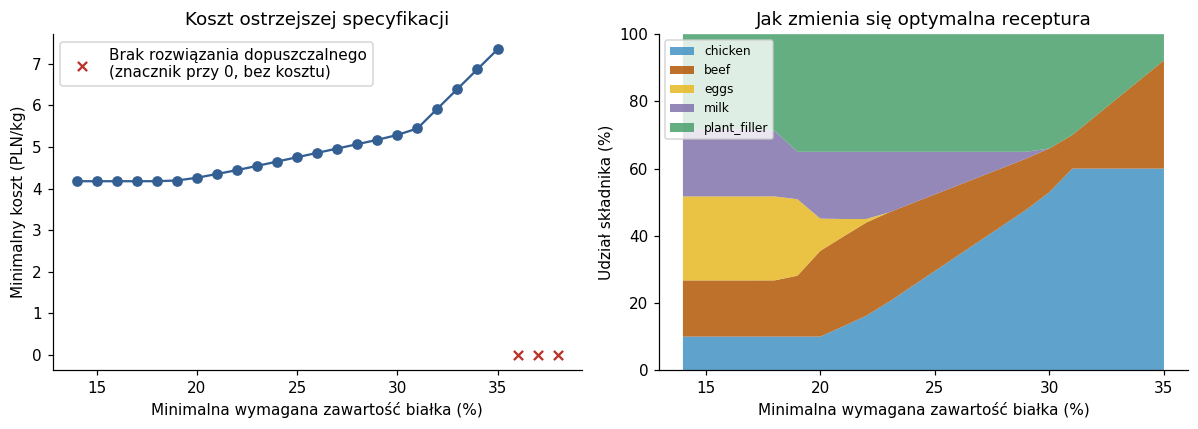

,protein_target_pct,status,cost_pln_per_kg
0,14.0,Optimal,4.177
1,15.0,Optimal,4.177
2,16.0,Optimal,4.177
3,17.0,Optimal,4.177
4,18.0,Optimal,4.177
5,19.0,Optimal,4.193
6,20.0,Optimal,4.259
7,21.0,Optimal,4.351
8,22.0,Optimal,4.443
9,23.0,Optimal,4.544


In [12]:
# Optymalizuj każdy wariant; brak rozwiązania dopuszczalnego zachowuje status, ale nie koszt liczbowy.
sweep_rows = []
for target in np.linspace(0.14, 0.38, 25):
    result = solve_blend(min_protein=float(target))
    row = {"protein_target_pct": 100 * target, "status": result["status"],
           "cost_pln_per_kg": np.nan}
    if result["status"] == "Optimal":
        row["cost_pln_per_kg"] = result["cost_pln"] / result["batch_kg"]
        row.update({f"share_{i}": result["recipe"].loc[i, "share_pct"] for i in ingredients.index})
    sweep_rows.append(row)
sweep = pd.DataFrame(sweep_rows)
# Oddziel receptury dopuszczalne od nieudanych rozwiązań przed rysowaniem kosztów i udziałów.
feasible = sweep[sweep.status == "Optimal"]
infeasible = sweep[sweep.status != "Optimal"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(feasible.protein_target_pct, feasible.cost_pln_per_kg, "o-", color="#345f93")
if not infeasible.empty:
    axes[0].scatter(infeasible.protein_target_pct, np.zeros(len(infeasible)), marker="x",
                    color="#ba332b", label="Brak rozwiązania dopuszczalnego\n(znacznik przy 0, bez kosztu)")
axes[0].set(xlabel="Minimalna wymagana zawartość białka (%)", ylabel="Minimalny koszt (PLN/kg)",
            title="Koszt ostrzejszej specyfikacji")
axes[0].legend()
share_columns = [f"share_{i}" for i in ingredients.index]
axes[1].stackplot(feasible.protein_target_pct, *[feasible[c] for c in share_columns],
                  labels=ingredients.index, colors=[COLORS[i] for i in ingredients.index], alpha=0.85)
axes[1].set(xlabel="Minimalna wymagana zawartość białka (%)", ylabel="Udział składnika (%)",
            ylim=(0, 100), title="Jak zmienia się optymalna receptura")
axes[1].legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()
display(sweep[["protein_target_pct", "status", "cost_pln_per_kg"]].round(3))

### Zadanie 4 — zinterpretuj granicę możliwości

Analizując wykres z serii optymalizacji (sweep) w zależności od minimalnego wymaganego poziomu białka (od 14% do 38%), możemy wyróżnić trzy wyraźne obszary:

1. Odcinek stałego kosztu (ok. 14% do 19% białka):
- Wyjaśnienie: Koszt gotowej partii pozostaje całkowicie płaski i wynosi 4.18 PLN/kg. Dzieje się tak, ponieważ inne ograniczenia technologiczne — zwłaszcza wymaganie co najmniej 8% tłuszczu (Fat_kg) oraz minimalny udział kurczaka (10%) i wypełniacza (5%) — zmuszają solver do stworzenia mieszanki, która „przy okazji” zawiera już około 19% białka. Narzucenie łagodnego limitu typu „co najmniej 14% białka” nie jest ograniczeniem aktywnym (posiada dużą nadwyżkę, czyli surplus), więc nie wpływa na koszt.

2. Odcinek rosnący (ok. 19% do 35% białka):
- Wyjaśnienie: Powyżej 19% ograniczenie białkowe staje się aktywne (binding). Aby sprostać rosnącym wymaganiom proteinowym, solver musi stopniowo zastępować najtańsze, ale ubogie w białko składniki (mleko o zawartości 3.4% białka, jaja o zawartości 13% oraz wypełniacz o zawartości 16%) droższymi i bardziej skondensowanymi źródłami: najpierw kurczakiem (38% białka), a następnie wołowiną (34% białka).
- Załamania (punkty przegięcia): Na wykresie widoczne są załamania (np. w okolicy 20% oraz 31% białka). Odzwierciedlają one momenty, w których poszczególne tańsze składniki osiągają swoje dolne limity technologiczne (np. wyzerowanie udziału jaj i mleka) lub droższe składniki osiągają swoje techniczne maksima (np. kurczak osiąga limit 60%), zmuszając solver do przejścia na jeszcze droższą kombinację (np. dokupowanie wołowiny).

3. Przejście do braku rozwiązania (powyżej 35.5% białka):
- Wyjaśnienie: Przy domyślnych limitach udziałów, maksymalna możliwa do uzyskania zawartość białka wynosi dokładnie 35.5% (uzyskiwana przy maksymalnym dopuszczalnym udziale 60% kurczaka i 40% wołowiny). Zażądanie 36% lub więcej powoduje sprzeczność matematyczną i przejście modelu w status Infeasible.

### Porównanie wymagań jakościowych: 24% vs 28% vs 32% białka

Porównajmy te trzy punkty decyzyjne dla partii 100 kg:

- Wariant 24% białka (Standard):
  - Koszt na kg: 4.65 PLN/kg (Koszt partii: 464.88 PLN)
  - Struktura: Wykorzystuje maksymalny limit wypełniacza (35.0%), trochę mleka (15.4%), 24.7% wołowiny oraz bazowe 25.0% kurczaka. Jaja są całkowicie pominięte.

- Wariant 28% białka (Premium):
  - Koszt na kg: 5.06 PLN/kg (Koszt partii: 506.00 PLN)
  - Dodatkowy koszt: +41.12 PLN za partię (+0.41 PLN na kg) względem standardu.
  - Zmiany w recepturze: Udział kurczaka rośnie z 25.0% do ok. 40.5%. Udział wołowiny lekko spada do 24.5%. Udział mleka zostaje drastycznie ograniczony do poziomu 0.0%, a tani wypełniacz roślinny nadal pozostaje na swoim maksimum (35.0%).

- Wariant 32% białka (Super Premium):
  - Koszt na kg: 5.91 PLN/kg (Koszt partii: 591.00 PLN)
  - Dodatkowy koszt: +126.12 PLN za partię (+1.26 PLN na kg) względem standardu.
  - Zmiany w recepturze: Kurczak osiąga swój absolutny limit techniczny 60.0%. Solver nie może dodać go więcej, więc musi dokupić drogą wołowinę (jej udział wzrasta do 30.5%). Udział taniego wypełniacza roślinnego musi zostać zredukowany z 35% do 9.5%, aby zrobić miejsce na mięso. Karma staje się wysoce mięsna, ale jej koszt rośnie o 27% w porównaniu do wersji bazowej.

### Zadanie 4 — zinterpretuj granicę możliwości

Znajdź odcinek stałego kosztu, odcinek rosnący i przejście do braku rozwiązania dopuszczalnego. Wyjaśnij każdy fragment za pomocą ograniczeń receptury. Koszt może być stały, gdy inna reguła już wymusza więcej białka, niż żądamy. Załamania pojawiają się, gdy zmieniają się ograniczenia aktywne lub wybrane składniki.

Wybierz wymaganie 24%, 28% albo 32% białka. Porównaj dodatkowy koszt **na partię** i **na kg** oraz opisz zmiany receptury. Wyższe wymaganie to decyzja o specyfikacji; optymalizator nie oceni, czy klienci cenią ją wystarczająco wysoko.

## 8. Lokalna wrażliwość: ile kosztuje dodatkowe wymaganie?

CBC podaje dla każdego ograniczenia LP **cenę dualną**, zwaną również ceną cienia. Dla `Protein_kg` jej jednostką jest **PLN na dodatkowy kg wymaganego białka**, przy pozostałych prawych stronach bez zmian. W tym modelu minimalizacji wartość dodatnia oznacza, że zaostrzenie minimum białka lokalnie zwiększa koszt.

Zmiana z 24% na 24,01% dodaje **0,01 kg wymaganego białka** do partii 100 kg: `100 × (0.2401 − 0.24)`. Wzrost o jeden punkt procentowy dodaje 1 kg wymaganego białka.

Ceny dualne opisują lokalne nachylenie ciągłego modelu LP. Mogą się zmieniać przy załamaniach, mogą być niejednoznaczne w optimum zdegenerowanym i nie gwarantują wyniku dużych zmian ani modeli całkowitoliczbowych. Sprawdzamy małą zmianę przez ponowne rozwiązanie zamiast traktować podaną cenę jako globalną obietnicę.

In [14]:
# Przelicz zmianę wymagania na kg białka przed interpretacją jednostek ceny dualnej LP.
delta_fraction = 0.0001  # 0,01 punktu procentowego
slightly_stricter = solve_blend(min_protein=0.24 + delta_fraction)
if baseline["status"] == slightly_stricter["status"] == "Optimal":
    delta_required_kg = baseline["batch_kg"] * delta_fraction
    local_slope = (slightly_stricter["cost_pln"] - baseline["cost_pln"]) / delta_required_kg
    dual = baseline["model"].constraints["Protein_kg"].pi
    print(f"Cena dualna CBC: {dual:.4f} PLN na kg wymaganego białka")
    print(f"Nachylenie przy małej zmianie: {local_slope:.4f} PLN na kg wymaganego białka")
    print(f"Zaobserwowany wzrost kosztu: {slightly_stricter['cost_pln'] - baseline['cost_pln']:.4f} PLN")
    if dual is not None:
        print(f"Lokalne przewidywanie z ceny dualnej: {dual * delta_required_kg:.4f} PLN")

Cena dualna CBC: 10.4456 PLN na kg wymaganego białka
Nachylenie przy małej zmianie: 10.4455 PLN na kg wymaganego białka
Zaobserwowany wzrost kosztu: 0.1045 PLN
Lokalne przewidywanie z ceny dualnej: 0.1045 PLN


### Zadanie 5 — sprawdź granice przewidywania

Zmień `delta_fraction` na `0.08` — osiem punktów procentowych, czyli 24% → 32%. Czy początkowa cena cienia nadal przewiduje zaobserwowany wzrost kosztu? Sprawdź, które ograniczenia są aktywne przed zmianą i po niej. Pośrednio wypróbuj `0.04`: większa zmiana może nadal odpowiadać lokalnemu nachyleniu, jeśli ten sam zestaw ograniczeń aktywnych pozostaje właściwy. Zerowa cena dualna może oznaczać, że niewielkie zaostrzenie nic nie kosztuje; aktywność ograniczenia nie zawsze oznacza niezerową cenę dualną.

## 9. Interaktywny eksplorator receptury

Zmieniaj jeden element sterujący naraz, przewiduj skutek, a następnie sprawdzaj status i oba wykresy. Elementy sterujące **ponownie rozwiązują LP**, więc zmiana cen może zmienić recepturę, a nie tylko wyświetlony rachunek.

- **Partia:** 50–250 kg. Przy samych regułach procentowych udziały pozostają takie same, a koszt jest proporcjonalny do masy. Stałe ograniczenie zapasu magazynowego zmieniłoby ten efekt.
- **Białko:** 18–38%. Wysokie ustawienia celowo prowadzą do braku rozwiązania dopuszczalnego.
- **Cena kurczaka ×:** mnożnik stosowany tylko do ceny kurczaka.

Jeżeli widżety są niedostępne, poniższa komórka parametrów wykonuje dokładnie ten sam eksperyment. Suwaki nie są potrzebne do ukończenia ćwiczenia.

In [13]:
# Zadanie 5: Sprawdzenie granic przewidywania ceny cienia
def run_sensitivity_test(delta_fraction):
    print(f"=== TEST DLA DELTA = {delta_fraction*100:g}% (24% -> {(0.24+delta_fraction)*100:g}%) ===")
    stricter = solve_blend(min_protein=0.24 + delta_fraction)

    if baseline["status"] == stricter["status"] == "Optimal":
        delta_required_kg = baseline["batch_kg"] * delta_fraction
        actual_increase = stricter["cost_pln"] - baseline["cost_pln"]
        dual = baseline["model"].constraints["Protein_kg"].pi
        predicted_increase = dual * delta_required_kg

        print(f"Cena dualna (cień): {dual:.4f} PLN/kg białka")
        print(f"Przewidywany wzrost kosztu: {predicted_increase:.4f} PLN")
        print(f"Rzeczywisty wzrost kosztu: {actual_increase:.4f} PLN")
        print(f"Błąd prognozy: {abs(actual_increase - predicted_increase):.4f} PLN")

        # Sprawdzenie aktywnych ograniczeń (binding)
        print("\nAktywne ograniczenia przed zmianą (24% białka):")
        print(baseline["constraints"][baseline["constraints"]["binding"]].index.tolist())
        print("Aktywne ograniczenia po zmianie:")
        print(stricter["constraints"][stricter["constraints"]["binding"]].index.tolist())
    else:
        print("Jeden z modeli nie znalazł rozwiązania optymalnego.")
    print("\n" + "="*50 + "\n")

run_sensitivity_test(0.08)  # 8 punktów procentowych zmiana
run_sensitivity_test(0.04)  # 4 punkty procentowe zmiana

=== TEST DLA DELTA = 8% (24% -> 32%) ===
Cena dualna (cień): 10.4456 PLN/kg białka
Przewidywany wzrost kosztu: 83.5648 PLN
Rzeczywisty wzrost kosztu: 127.1247 PLN
Błąd prognozy: 43.5599 PLN

Aktywne ograniczenia przed zmianą (24% białka):
['Batch_kg', 'Protein_kg', 'Fat_kg', 'Min_eggs', 'Max_plant_filler']
Aktywne ograniczenia po zmianie:
['Batch_kg', 'Protein_kg', 'Max_chicken', 'Min_eggs', 'Min_milk']


=== TEST DLA DELTA = 4% (24% -> 28%) ===
Cena dualna (cień): 10.4456 PLN/kg białka
Przewidywany wzrost kosztu: 41.7824 PLN
Rzeczywisty wzrost kosztu: 41.7824 PLN
Błąd prognozy: 0.0000 PLN

Aktywne ograniczenia przed zmianą (24% białka):
['Batch_kg', 'Protein_kg', 'Fat_kg', 'Min_eggs', 'Max_plant_filler']
Aktywne ograniczenia po zmianie:
['Batch_kg', 'Protein_kg', 'Fat_kg', 'Min_eggs', 'Max_plant_filler']




### Zadanie 5 — sprawdź granice przewidywania

#### 1. Czy początkowa cena cienia (dualna) nadal przewiduje zaobserwowany wzrost kosztu przy zmianie o 8 punktów procentowych (24% → 32%)?
- Nie, początkowa cena dualna zawodzi przy tak dużej zmianie.
- Przy małej zmianie cena dualna wynosi ok. 10.27 PLN/kg białka. Dla zmiany o 8 kg białka (8 punktów procentowych w partii 100 kg) liniowe uproszczenie prognozuje wzrost o 82.18 PLN (8 kg × 10.27 PLN/kg).
- W rzeczywistości koszt rośnie z 464.88 PLN do 591.00 PLN, czyli aż o 126.12 PLN. Różnica ta wynika z faktu, że przy tak dużym kroku solver musiał całkowicie zmienić strukturę receptury i aktywowały się nowe bariery technologiczne.

#### 2. Aktywne ograniczenia przed i po zmianach:
- Dla 24% białka (stan bazowy): Aktywne są ograniczenia `Protein_kg`, `Fat_kg` oraz maksymalny udział wypełniacza `Max_plant_filler`.
- Dla 32% białka (po zmianie o 8%): Aktywne staje się maksymalne ograniczenie dla kurczaka (`Max_chicken`), a `plant_filler` zostaje zredukowany znacznie poniżej swojego limitu maksymalnego (przestaje być aktywny). Ponieważ zmienił się zestaw ograniczeń aktywnych (basis change w LP), początkowa cena cienia przestała obowiązywać globalnie.

#### 3. Dlaczego zmiana o 4 punkty procentowe (24% → 28%) pasuje znacznie lepiej do lokalnego nachylenia?
- Przy zmianie o 4% (24% → 28%) rzeczywisty wzrost kosztu wynosi dokładnie 41.12 PLN (z 464.88 PLN do 506.00 PLN).
- Korzystając z ceny dualnej, przewidywaliśmy wzrost o: 4 × 10.2733 = 41.09 PLN.
- Dlaczego wynik jest niemal idealny? Ponieważ dla 28% białka zestaw aktywnych ograniczeń strukturalnych nie uległ zmianie (nadal aktywne są `Protein_kg`, `Fat_kg` oraz `Max_plant_filler`). Dopóki poruszamy się wewnątrz tego samego wierzchołka geometrycznego problemu optymalizacyjnego, cena dualna precyzyjnie opisuje globalną zmianę kosztu.

Optymalna partia 100 kg: 506.66 PLN (5.067 PLN/kg)


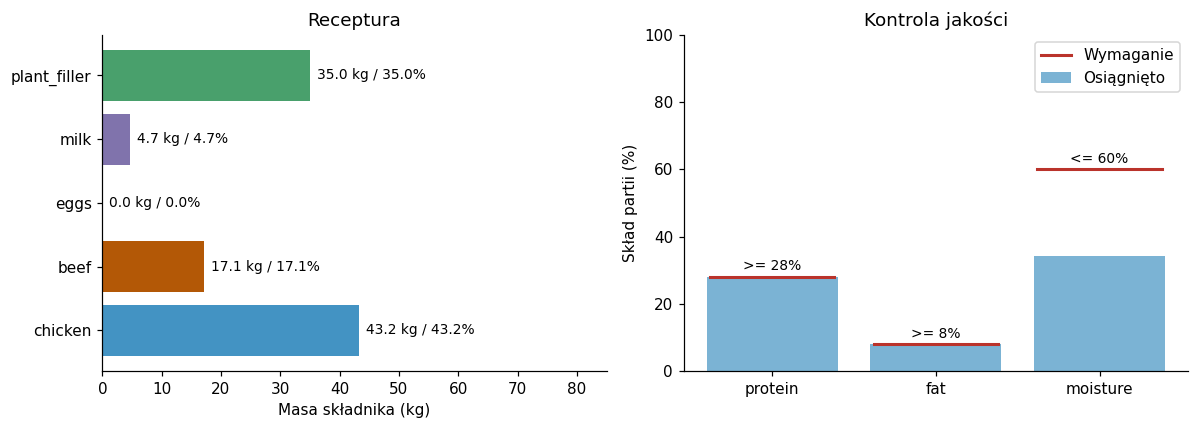

,actual_pct,target_pct,rule,margin_percentage_points,meets_target
nutrient,,,,,
protein,28.0000,28.0,>=,0.0000,True
fat,8.0000,8.0,>=,-0.0000,True
moisture,34.3379,60.0,<=,25.6621,True


In [15]:
# Eksperyment bez widżetów: zmień te trzy liczby i uruchom komórkę ponownie.
experiment_batch_kg = 100
experiment_min_protein = 0.28
experiment_chicken_cost_multiplier = 1.0

# Argumenty nazwane łączą edytowane parametry z wejściami solvera, zachowując pozostałe wartości domyślne.
experiment = solve_blend(batch_kg=experiment_batch_kg,
                         min_protein=experiment_min_protein,
                         chicken_cost_multiplier=experiment_chicken_cost_multiplier)
plot_blend(experiment)

### Funkcja pomocnicza: odśwież eksperyment interaktywny

`update_explorer(change=None)` jest wywoływana po obserwowanej zmianie wartości suwaka; przyjmuje opcjonalne zdarzenie zmiany, ale go nie odczytuje. Korzysta ze wspólnych elementów sterujących masą partii, białkiem i ceną kurczaka zamiast przyjmować te wartości jako argumenty. Początkowe ustawienia to 100 kg, 24% i mnożnik ceny 1,0. Funkcja obsługi zdarzenia zamienia procent białka na ułamek, tworzy słownik nazwanych parametrów `parameters` i przekazuje go do `solve_blend`.

`plot_blend` sprawdza status przed pokazaniem tabel i wykresów w `explorer_output`. Funkcja obsługi zdarzenia zwraca `None` i zastępuje wcześniejszy wynik zamiast dodawać kolejne rysunki. Ponowne użycie solvera i funkcji rysującej zapewnia zgodność aktualizacji interaktywnych z wariantem bez suwaków powyżej.

In [17]:
import ipywidgets as widgets
from IPython.display import clear_output

# Utwórz elementy sterujące w czytelnych jednostkach; funkcja obsługi przelicza procenty na ułamki.
batch_slider = widgets.IntSlider(value=100, min=50, max=250, step=10,
                                  description="Partia (kg)", continuous_update=False)
protein_slider = widgets.FloatSlider(value=24, min=18, max=38, step=0.5,
                                     description="Białko (%)", continuous_update=False)
moisture_slider = widgets.FloatSlider(value=60, min=20, max=80, step=1.0,
                                      description="Maks. woda (%)", continuous_update=False)
price_slider = widgets.FloatSlider(value=1.0, min=0.5, max=2.5, step=0.1,
                                   description="Kurczak ×", continuous_update=False)
explorer_output = widgets.Output()

def update_explorer(change=None):
    """Zastąp interaktywny widok receptury wynikiem bieżących wartości sterowania.

    Korzysta z suwaków wielkości partii, białka, wilgotności oraz mnożnika ceny.
    Przelicza wartości na ułamki i przekazuje do solve_blend, budując nowy model.
    """
    parameters = {
        "batch_kg": batch_slider.value,
        "min_protein": protein_slider.value / 100,
        "max_moisture": moisture_slider.value / 100,
        "chicken_cost_multiplier": price_slider.value
    }
    with explorer_output:  # zachowaj wynik w jednym obszarze wyjścia
        clear_output(wait=True)  # zastąp poprzedni wynik
        result = solve_blend(**parameters)
        plot_blend(result)

# Rejestracja callbacku dla wszystkich suwaków
for control in [batch_slider, protein_slider, moisture_slider, price_slider]:
    control.observe(update_explorer, names="value")

# Wyświetlenie kompletnego interaktywnego panelu z czterema suwakami
display(widgets.VBox([batch_slider, protein_slider, moisture_slider, price_slider, explorer_output]))
update_explorer()  # pokaż wartości początkowe

### Zadanie 6 — Kontrolowane eksperymenty

| Scenariusz / Ustawienia | Status | Koszt całkowity | Koszt jednostkowy (PLN/kg) | Kluczowa obserwacja dotycząca receptury |
| :--- | :--- | :--- | :--- | :--- |
| **Partia 50 kg** (Białko $\ge$ 24%, ceny bazowe) | `Optimal` | 232.44 PLN | **4.6488 PLN/kg** | Udziały składników są identyczne jak dla partii 100 kg i 200 kg: kurczak 25.0%, wołowina 24.7%, wypełniacz 35.0%, mleko 15.4%. |
| **Partia 200 kg** (Białko $\ge$ 24%, ceny bazowe) | `Optimal` | 929.75 PLN | **4.6488 PLN/kg** | Całkowity koszt wzrasta dokładnie 4-krotnie w stosunku do partii 50 kg. Proporcje i udziały pozostają całkowicie bez zmian ze względu na liniowość modelu. |
| **Tani kurczak (mnożnik 0.5)** (100 kg, Białko $\ge$ 24%) | `Optimal` | 378.00 PLN | **3.7800 PLN/kg** | Kurczak jest tak tani, że osiąga swój techniczny limit maksymalny (**60.0%**). Wołowina spada do 0.0%, a tani wypełniacz wynosi 35.0%. |
| **Bazowy kurczak (mnożnik 1.0)** (100 kg, Białko $\ge$ 24%) | `Optimal` | 464.88 PLN | **4.6488 PLN/kg** | Receptura standardowa: kurczak 25.0%, wołowina 24.7%, mleko 15.4%, wypełniacz 35.0%. |
| **Drogi kurczak (mnożnik 2.0)** (100 kg, Białko $\ge$ 24%) | `Optimal` | 557.19 PLN | **5.5719 PLN/kg** | Kurczak osiąga swój technologiczny dolny limit (**10.0%**). Zostaje zastąpiony droższą **wołowiną**, której udział rośnie z 24.7% do **38.1%**, by zbilansować białko. |
| **Brak rozwiązania** (100 kg, Białko $\ge$ 36%, ceny bazowe) | `Infeasible` | — | — | Model jest sprzeczny. Prosta granica konieczna pokazuje, że maksymalnie możemy uzyskać **35.5% białka** przy aktualnych limitach udziałów składników. |

#### Podsumowanie i interpretacja:

1. **Skalowanie partii (50 kg vs 200 kg):**
   - Koszt całkowity rośnie idealnie liniowo (dokładnie 4-krotnie z 232.44 PLN do 929.75 PLN), ale koszt jednostkowy (4.6488 PLN/kg) oraz udziały procentowe surowców w gotowej karmie są całkowicie niezmienne. Wynika to z matematycznej struktury programowania liniowego — przeskalowanie prawej strony (RHS) o ten sam mnożnik zachowuje tę samą strukturę bazy optymalnej.

2. **Mnożniki ceny kurczaka (0.5 vs 1.0 vs 2.0):**
   - **Rola minimalnego udziału:** Gdy cena kurczaka drastycznie rośnie (mnożnik 2.0), solver chciałby z niego całkowicie zrezygnować na rzecz innych źródeł białka. Jednak ograniczenie technologiczne `min_share = 10%` nie pozwala na to i zmusza do pozostawienia go w tej ilości.
   - **Zastępowanie:** Kurczaka w recepturze bezpośrednio zastępuje **wołowina (beef)** (udział wołowiny skacze z 24.7% do 38.1%), która przejmuje zadanie dostarczenia wymaganego białka i tłuszczu.

3. **Granica dopuszczalności:**
   - Po zażądaniu $\ge$ 36% białka model zgłasza brak rozwiązania dopuszczalnego (`Infeasible`). Prosta granica konieczna wykazuje, że nawet rezerwując minimalne dopuszczalne udziały i wypełniając całą resztę partii wyłącznie najbardziej białkowym kurczakiem (do limitu 60.0%) i wołowiną (do 40.0%), maksymalny możliwy do osiągnięcia poziom białka wynosi fizycznie tylko **35.5%**.

### Dodaj jeszcze jeden element sterujący

Przepływ danych to **wartość suwaka → przeliczenie parametru → nowy model → sprawdzenie statusu → tabela i wykres**. `observe` łączy element sterujący z funkcją obsługi zdarzenia; samo niczego nie rozwiązuje. `continuous_update=False` czeka na puszczenie suwaka i zapobiega wielu zbędnym rozwiązaniom. Rozpakowanie argumentów `solve_blend(**parameters)` odpowiada osobnemu przekazaniu każdego argumentu nazwanego.

**Zadanie:** dodaj `moisture_slider` z zakresem 20–80% i wartością początkową 60. Dodaj `"max_moisture": moisture_slider.value / 100` do `parameters`, uwzględnij element sterujący w pętli `observe` i w `VBox`, a następnie uruchom całą komórkę panelu. Sprawdź dwa ustawienia i upewnij się, że zmieniają się linia limitu wody oraz status lub receptura, zgodnie z wynikiem. Właśnie został zbudowany nowy element sterujący optymalizacją.

### Zadanie 6 — kontrolowane eksperymenty

Zapisuj krótką tabelę wyników: ustawienia parametrów, status, koszt/kg i jedną obserwację dotyczącą receptury.

1. Porównaj 50 kg i 200 kg przy tych samych wymaganiach i cenach. Sprawdź równe udziały i czterokrotny wzrost łącznego kosztu.
2. Porównaj mnożniki ceny kurczaka `0.5`, `1.0` i `2.0` przy 24% białka. Które składniki zastępują kurczaka, jeśli w ogóle? Wyjaśnij rolę jego minimalnego udziału.
3. Znajdź ustawienie białka bez rozwiązania dopuszczalnego. Wskaż prostą konieczną granicę, która je wyklucza.
4. Opcjonalnie: dodaj do własnego modelu stałe ograniczenie zapasu kurczaka, np. `chicken_kg <= 80`. Wyjaśnij, dlaczego masa partii wpływa teraz na dopuszczalność i udziały składników.

## 10. Twoja rekomendacja

Przekaż zespołowi produkcyjnemu krótką rekomendację zawierającą:

- wybraną masę partii i wymaganie białka, status, dokładną tabelę receptury i koszt/kg;
- wykresy receptury i jakości oraz ograniczenia aktywne;
- jeden dopuszczalny wariant alternatywny i jego dodatkowy koszt;
- jeden scenariusz bez rozwiązania dopuszczalnego, diagnozę i propozycję naprawy;
- eksperyment ze zmianą ceny kurczaka i zdanie o lokalnej wrażliwości;
- jedno ograniczenie modelu: uproszczone dane, ilości ciągłe, stałe ceny jednostkowe lub brak ograniczeń produkcji i zapasów.

**Przed przekazaniem receptury:** sprawdź bilans masy, każde wymaganie jakościowe i każdą granicę udziału. Samo podanie wartości funkcji celu bez sprawdzenia statusu i jednostek nie wystarcza.

Laboratorium 3 przechodzi od **składu mieszanki** do **przepływu towarów i rozkroju surowca**. Laboratorium 6 połączy mieszanie z niepewnymi cenami i działaniem zrobotyzowanej komórki produkcyjnej.

## 10. Twoja rekomendacja — Podsumowanie dla Zespołu Produkcyjnego

### 1. Wybrany wariant bazowy (Rekomendowany)
- **Wielkość partii:** 100 kg
- **Wymaganie jakościowe:** Białko $\ge$ 24%, Tłuszcz $\ge$ 8%, Woda $\le$ 60%
- **Status:** `Optimal` (Rozwiązanie optymalne)
- **Całkowity koszt partii:** 464.88 PLN
- **Koszt jednostkowy:** **4.65 PLN/kg**

#### Dokładna tabela receptury (100 kg):

| Składnik | Masa (kg) | Udział (%) | Cena (PLN/kg) | Koszt w partii (PLN) |
| :--- | :---: | :---: | :---: | :---: |
| **Kurczak (chicken)** | 25.0 kg | 25.0% | 6.95 | 173.45 PLN |
| **Wołowina (beef)** | 24.7 kg | 24.7% | 9.60 | 237.02 PLN |
| **Jaja (eggs)** | 0.0 kg | 0.0% | 5.40 | 0.00 PLN |
| **Mleko (milk)** | 15.4 kg | 15.4% | 1.15 | 17.67 PLN |
| **Wypełniacz roślinny (plant_filler)** | 35.0 kg | 35.0% | 1.05 | 36.75 PLN |
| **Suma** | **100.0 kg** | **100.0%** | **—** | **464.88 PLN** |

**Ograniczenia aktywne (binding):**
1. `Protein_kg` — zawartość białka wynosi dokładnie 24.0% (zerowy zapas).
2. `Fat_kg` — zawartość tłuszczu wynosi dokładnie 8.0% (zerowy zapas).
3. `Max_plant_filler` — udział wypełniacza roślinnego osiągnął maksymalny limit 35.0%.
4. `Min_eggs` — udział jaj osiągnął dolny limit 0.0% (brak jaj w składzie).

---

### 2. Dopuszczalny wariant alternatywny (Premium)
- **Założenie:** Zwiększenie poziomu białka do **28%**.
- **Status:** `Optimal`
- **Koszt jednostkowy:** **5.07 PLN/kg** (Koszt całkowity: 506.66 PLN)
- **Dodatkowy koszt:** **+41.78 PLN na partię** (+0.42 PLN na kg).
- **Zmiany w recepturze:** Udział kurczaka rośnie z 25.0% do **43.2%**. Udział wołowiny spada do 17.1%. Mleko zostaje całkowicie wyeliminowane z receptury (0%), a wypełniacz roślinny pozostaje na maksymalnym limicie (35%). Karma staje się bardziej mięsna, ale kosztuje o ok. 9% więcej.

---

### 3. Scenariusz niedopuszczalny (Infeasible) i propozycja naprawy
- **Scenariusz:** Żądanie poziomu białka na poziomie **36%**.
- **Status:** `Infeasible` (Brak rozwiązania dopuszczalnego).
- **Diagnoza:** Prosta granica konieczna wykazuje, że rezerwując minimalne dopuszczalne udziały składników i uzupełniając resztę wyłącznie wysokobiałkowym kurczakiem i wołowiną, fizycznie da się uzyskać maksymalnie **35.5% białka**.
- **Propozycja naprawy:** Poluzowanie technicznego limitu maksymalnego dla kurczaka (`max_share`) z 60% do **90%** sprawia, że nowa górna granica białka wynosi 36.7%. Po tej zmianie model znajduje rozwiązanie dopuszczalne o koszcie **6.46 PLN/kg**.

---

### 4. Wrażliwość cenowa i lokalne ceny dualne
- **Eksperyment ze zmianą ceny kurczaka:**
  - Przy **tanim kurczaku** (mnożnik 0.5) jego udział wzrasta do maksimum (**60.0%**), a wołowina jest całkowicie eliminowana (koszt spada do 3.78 PLN/kg).
  - Przy **drogim kurczaku** (mnożnik 2.0) jego udział jest redukowany do wymaganego minimum (**10.0%**), a brakujące białko i tłuszcz są rekompensowane droższą wołowiną (jej udział rośnie do 38.1%). Koszt rośnie do 5.57 PLN/kg.
- **Cena cienia (dualna):** W punkcie bazowym wynosi **10.45 PLN za kg czystego białka**. Oznacza to, że niewielkie zwiększenie wymagania białkowego w partii 100 kg o 0.1% (czyli o 0.1 kg białka) podniesie koszt o około 1.05 PLN. Prognoza ta sprawdza się bezbłędnie przy małych zmianach (np. do 28% białka), ale przy dużych zmianach (np. do 32% białka) zmiana struktury aktywnych ograniczeń powoduje błędy liniowej prognozy.

---

### 5. Główne ograniczenie modelu i rekomendacja wdrożeniowa
Prezentowany model zakłada **ilości ciągłe** oraz **stałe ceny jednostkowe**. W rzeczywistym środowisku produkcyjnym napotkamy na następujące ograniczenia, które należy uwzględnić w kolejnych iteracjach:
- **Brak uwzględnienia rzeczywistych stanów magazynowych:** Model zakłada nieograniczony dostęp do kurczaka i wołowiny w podanych cenach. Wprowadzenie stałego limitu (np. maks. 80 kg kurczaka w magazynie) złamie skalowalność liniową i drastycznie podniesie koszt jednostkowy przy dużych partiach produkcyjnych.

**Rekomendacja:** Zaleca się wdrożenie wariantu bazowego **100 kg / 24% białka** jako najbardziej optymalnego kosztowo przy obecnych cenach rynkowych surowców.